# Unidad 3 · Práctica 3 — Sin etiqueta

Ciencia de Datos · UTN FRM · 2026

Tercera y última clase práctica de la unidad. Se corre **de arriba hacia abajo**; la primera celda
de código reconstruye lo que dejaron las dos prácticas anteriores. Cada título es una celda propia,
así que el índice de Colab (el panel de la izquierda) sirve para saltar entre secciones, y las
secciones se pueden plegar desde la flecha del título.

Las dos prácticas anteriores necesitaron `y`: quince mil jugadores con su rol escrito. Esta clase
hace la pregunta que quedó abierta al final de la Práctica 2: **¿qué se puede aprender de los
mismos datos sin la etiqueta?** Y la versión concreta: ¿hay grupos ahí adentro, y se parecen a los
siete roles con los que se venía trabajando?

## Hoja de ruta

| Parte | Qué pasa | Qué deja |
|---|---|---|
| **1** | Sin etiqueta: qué cambia | qué se puede medir y qué no cuando no hay `y`; el primer paso de todos los pipelines |
| **2** | PCA: de 34 habilidades a pocas direcciones | leer una componente, elegir cuántas, mirar el dataset en dos y tres ejes |
| **3** | Clustering: dos definiciones de grupo | k-means y DBSCAN sobre PC1 y PC2; elegir *k* y `eps`, adentro del pipeline; leer una silueta |
| **4** | Sin los arqueros | sacarlos como un paso del pipeline, y ver qué cambia en PCA, en k-means y en DBSCAN |
| **5** | Lo que le deja al supervisado | PCA como paso de `preparar` de tres modelos, medido; qué espera la Entrega 3 de un proyecto sin etiqueta |

## Antes de empezar

Hace falta el mismo `fifa_canonico_2026-07-23.csv` de siempre; la celda lo baja si no está. La
segunda celda es el preámbulo de las prácticas anteriores: el dataset, los siete roles, las columnas
que salen por fuga y el pipeline de la Práctica 1. Hoy `y` no se usa para aprender; se guarda en
`rol` y aparece sólo para *mirar*, y cada vez que aparece se dice.

In [ ]:
# El dataset se baja del Drive de la cátedra la primera vez que se corre el notebook
import os

ARCHIVO  = "fifa_canonico_2026-07-23.csv"
ID_DRIVE = "1cF30_fSvxNKpK5-AKJlzUqLHZTTUf0ls"

if not os.path.exists(ARCHIVO):
    !gdown $ID_DRIVE -O $ARCHIVO

In [ ]:
# Todo lo que dejaron las prácticas anteriores, en un bloque
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings("ignore")

from sklearn.model_selection import train_test_split
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 160)

SEMILLA = 42
df = pd.read_csv(ARCHIVO, low_memory=False)

# el objetivo: de quince posiciones a siete roles
GRUPO = {"GK": "Arquero", "CB": "Defensor central",
         "LB": "Lateral", "RB": "Lateral", "LWB": "Lateral", "RWB": "Lateral",
         "CDM": "Volante defensivo",
         "CM": "Volante", "CAM": "Volante", "LM": "Volante", "RM": "Volante",
         "LW": "Extremo", "RW": "Extremo", "ST": "Delantero", "CF": "Delantero"}
rol = df["best_position"].map(GRUPO)   # hoy no es y: es la etiqueta que se guarda para mirar al final

# las columnas que no pueden estar
FUGA = ["best_position", "player_positions", "club_position", "best_overall"]
IDS  = ["player_id", "short_name", "long_name", "player_url", "player_face_url",
        "club_team_id", "club_name", "nationality_id", "nationality_name",
        "league_id", "league_name", "league_country", "fifa_version", "fifa_update",
        "fifa_update_date", "club_joined_date", "club_loan_end_date",
        "club_jersey_number", "club_contract_valid_until_year", "player_traits"]
X = df.drop(columns=FUGA + IDS)

# el transformador propio
DERIVADAS = ["def_menos_ata", "fisico_menos_tecnica", "pase_menos_gambeta"]

class DiferenciasDeHabilidades(BaseEstimator, TransformerMixin):
    '''Agrega tres columnas que restan habilidades entre sí.'''

    def __init__(self, relativo=False):
        self.relativo = relativo

    def fit(self, X, y=None):
        self.feature_names_in_ = np.asarray(X.columns)
        return self

    def transform(self, X):
        nuevas = pd.DataFrame({"def_menos_ata":        X["defending"] - X["shooting"],
                               "fisico_menos_tecnica": X["physic"]    - X["dribbling"],
                               "pase_menos_gambeta":   X["passing"]   - X["dribbling"]},
                              index=X.index)
        if self.relativo:
            nuevas = nuevas.div(X["overall"], axis=0)
        return pd.concat([X, nuevas], axis=1)

    def get_feature_names_out(self, input_features=None):
        return np.concatenate([self.feature_names_in_, DERIVADAS])

# la receta completa
NUMERICAS   = X.select_dtypes("number").columns.tolist()
CATEGORICAS = [c for c in X.columns if c not in NUMERICAS]

preparar = ColumnTransformer([
    ("numericas", Pipeline([("imputar", SimpleImputer(strategy="median")),
                            ("escalar", StandardScaler())]),
     NUMERICAS + DERIVADAS),
    ("categoricas", Pipeline([("imputar",   SimpleImputer(strategy="most_frequent")),
                              ("codificar", OneHotEncoder(handle_unknown="ignore"))]),
     CATEGORICAS)])

pipeline_completo = Pipeline([("derivar",      DiferenciasDeHabilidades()),
                              ("preparar",     preparar),
                              ("clasificador", LogisticRegression(max_iter=3000))])

pd.Series({"jugadores": len(X), "columnas": X.shape[1]})

jugadores    18936
columnas        66
dtype: int64

## Parte 1 — Sin etiqueta: qué cambia

En las dos prácticas anteriores había una respuesta correcta por fila, y con ella una métrica, una
validación cruzada y un test. Sin `y` no hay nada de eso: no hay f1 que calcular, y ningún
conjunto de validación puede decir si se acertó, porque no hay con qué comparar. Lo que queda son
dos cosas:

- **Medidas internas**: cuánto se parecen entre sí los jugadores que quedaron juntos, y cuánto se
  diferencian de los que quedaron aparte. Son números, pero no dicen si los grupos *significan*
  algo.
- **El ojo**: proyectar, dibujar, mirar quién quedó con quién. Es el método más viejo de la
  estadística, y sigue siendo el que decide.

Y una regla nueva, que en supervisado no hacía falta: **la escala es parte del modelo.** Un
algoritmo que agrupa por distancia trata un punto de `overall` igual que un euro de salario; si una
columna va de 0 a 100 y otra de 0 a 100.000.000, la segunda decide sola. Acá se trabaja con las 34
habilidades detalladas —las que describen qué sabe hacer un jugador—, que ya están todas entre 1 y
99, así que escalar cambia poco — pero se escala igual, porque en el integrador las columnas no van
a ser tan amables.

La forma de trabajar es la de siempre: cada modelo es un **`Pipeline`** que recibe `X` entera, con
sus 66 columnas, y adentro decide qué usar. Elegir las 34 habilidades y escalarlas es el primer paso
de todos los pipelines de hoy: un `ColumnTransformer` con una sola regla, `StandardScaler` sobre las
columnas que elige un `make_column_selector` por nombre, y el resto de las columnas se descarta
(`remainder="drop"`, que es lo que hace si no se le dice otra cosa). Lo que cambia respecto de las
prácticas anteriores es el último paso: no predice, proyecta o agrupa.

Una regla que vale para todo el notebook, y que conviene decir de entrada: **cada cambio en un
resultado tiene que poder explicarse por un paso del pipeline.** Si dos números difieren, es porque
difieren los pipelines que los produjeron, y la diferencia se señala con el dedo.

In [ ]:
from sklearn.preprocessing import StandardScaler
from sklearn.compose import make_column_selector

def habilidades():
    '''El primer paso de todos los pipelines de hoy: quedarse con las 34 habilidades detalladas y escalarlas.'''
    detalladas = make_column_selector(pattern="^(?!skill_moves)(attacking|skill|movement|power|mentality|defending|goalkeeping)_")
    return ColumnTransformer([("escalar", StandardScaler(), detalladas)], verbose_feature_names_out=False)

# qué sale de ese paso, sobre X entera: 34 columnas con media 0 y desvío 1 (se muestran dos)
paso = habilidades().fit(X)
DETALLADAS = list(paso.get_feature_names_out())   # los nombres, para rotular gráficos; el pipeline no los necesita
salida = pd.DataFrame(paso.transform(X), columns=DETALLADAS, index=X.index)
print(len(DETALLADAS), "columnas, sin nulos:", not salida.isna().any().any())
pd.DataFrame({"media original": X[DETALLADAS].mean(), "desvío original": X[DETALLADAS].std(),
              "media escalada": salida.mean().round(6), "desvío escalado": salida.std()}).round(2).loc[["movement_sprint_speed", "goalkeeping_diving"]]

34 columnas, sin nulos: True


,media original,desvío original,media escalada,desvío escalado
movement_sprint_speed,64.96,15.05,0.0,1.0
goalkeeping_diving,16.19,17.48,-0.0,1.0


Escaladas, cada columna queda con media 0 y desvío 1: un jugador que está un desvío arriba en
velocidad cuenta lo mismo que uno que está un desvío arriba en atajadas. El `paso` de arriba se
armó sólo para mirar qué hace y para rescatar los 34 nombres; de acá en adelante vive adentro de
cada pipeline y no se lo vuelve a tocar.

## Parte 2 — PCA: de 34 habilidades a pocas direcciones

Treinta y cuatro columnas no se pueden mirar. **El análisis de componentes principales** busca
las direcciones en las que los jugadores más se diferencian entre sí: la primera componente es la
combinación lineal de las 34 habilidades con mayor varianza, la segunda es la de mayor varianza
entre las perpendiculares a la primera, y así. No usa ninguna etiqueta; sólo mira cómo se
reparten los puntos.

**Qué clase de objeto es `PCA`.** En scikit-learn, todo lo que aprende de los datos es un
**estimador**: tiene `fit`. Lo que lo distingue es qué sabe hacer después de aprender:

- un **predictor** tiene `predict`: la logística, el árbol, el boosting de las prácticas anteriores;
- un **transformador** tiene `transform`: el `StandardScaler`, el `OneHotEncoder`… y `PCA`.

`PCA` es un estimador porque en `fit` aprende las direcciones, y es un transformador porque en
`transform` proyecta cada jugador sobre ellas. No predice nada. Por eso puede ser el último paso de
un pipeline —el pipeline entero se vuelve un transformador— o un paso intermedio antes de otro
modelo (la Parte 3 lo usa así).

Y lo que aprende queda guardado en el objeto, como siempre: los **parámetros aprendidos** son los
atributos que terminan en guión bajo —`components_`, `explained_variance_ratio_`—, y se los
distingue así de los **hiperparámetros**, que se eligen antes de `fit` y no llevan guión bajo
—`n_components`—. Todo lo que se muestra en esta parte sale de leer esos atributos del pipeline
ajustado, con `reducir["pca"]`; no se calcula nada aparte.

### 2.1 Cuánta varianza se queda en cada componente

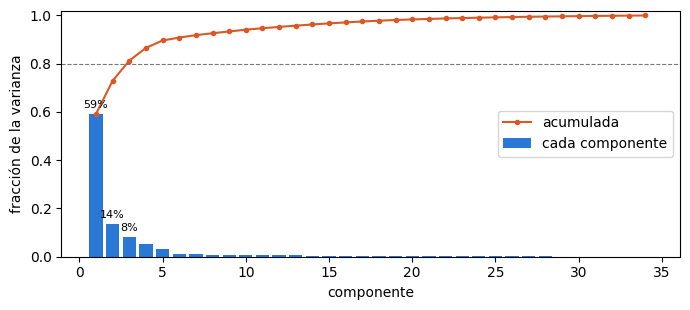

In [ ]:
from sklearn.decomposition import PCA

reducir = Pipeline([("habilidades", habilidades()),
                    ("pca",         PCA(random_state=SEMILLA))]).fit(X)

def graficar_varianza(ax, pca, color_barras="#2a78d6", color_linea="#d95926", nombre="", corrimiento=0, ancho=0.8):
    # explained_variance_ratio_: la fracción de la varianza total que se queda cada componente, aprendida en fit
    v = pca.explained_variance_ratio_
    x = np.arange(1, len(v) + 1) + corrimiento
    ax.bar(x, v, width=ancho, color=color_barras, label=f"cada componente {nombre}".strip())
    ax.plot(x, v.cumsum(), marker="o", markersize=3, color=color_linea, label=f"acumulada {nombre}".strip())
    for i in range(3):   # las tres primeras, con su valor
        ax.annotate(f"{v[i]:.0%}", (x[i], v[i]), textcoords="offset points", xytext=(0, 4), ha="center", fontsize=8)
    ax.axhline(0.8, color="#7a7974", lw=0.8, ls="--")
    ax.set_xlabel("componente"); ax.set_ylabel("fracción de la varianza"); ax.set_ylim(0, 1.02)
    ax.legend(loc="center right")

fig, ax = plt.subplots(figsize=(7, 3.2))
graficar_varianza(ax, reducir["pca"])
plt.tight_layout()
plt.show()

La primera componente sola se queda con el **59 %** de la varianza, la segunda con el 14 % y la
tercera con el 8 %: tres direcciones explican el 81 % de lo que diferencia a dos jugadores en 34
habilidades. Con cinco se pasa el 90 %, y de ahí en adelante cada componente agrega menos del 2 %.
Es el patrón típico de un dataset con columnas muy correlacionadas: el que gambetea bien suele
pasar bien y controlar bien, así que esas tres columnas son casi una.

La línea de puntos en 0,8 es la convención más usada para elegir cuántas quedarse, y es una
convención, no una ley: depende de para qué. Para mirar, dos; para agrupar, las que superen el
umbral; para alimentar otro modelo, se mide como cualquier hiperparámetro (Parte 5).

### 2.2 Qué es cada componente

Una componente es una receta: tantos puntos de esta habilidad, menos tantos de aquella. Las recetas
están en `components_`, una fila por componente y una columna por habilidad. Las tres primeras,
mostrando sólo las seis habilidades que más pesan en cada una, para cada lado:

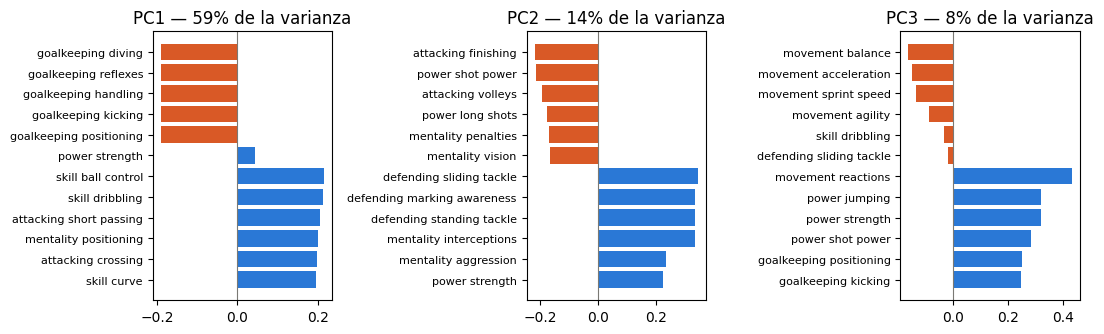

In [ ]:
def extremos(serie, n=6):
    '''Las n habilidades con carga más positiva y las n con carga más negativa.'''
    s = serie.sort_values()
    return pd.concat([s.head(n), s.tail(n)[::-1]])

def graficar_cargas(pca, titulo=""):
    fig, axes = plt.subplots(1, 3, figsize=(11, 3.6))
    for i, ax in enumerate(axes):
        # components_[i]: la receta de la componente i, una carga por habilidad
        s = extremos(pd.Series(pca.components_[i], index=DETALLADAS))
        ax.barh([h.replace("_", " ") for h in s.index][::-1], s.values[::-1],
                color=["#d95926" if v < 0 else "#2a78d6" for v in s.values[::-1]])
        ax.set_title(f"PC{i + 1} — {pca.explained_variance_ratio_[i]:.0%} de la varianza"); ax.axvline(0, color="#7a7974", lw=0.8)
        ax.tick_params(axis="y", labelsize=8)
    fig.suptitle(titulo, fontsize=10)
    plt.tight_layout()
    plt.show()

graficar_cargas(reducir["pca"])

Las tres recetas se leen:

- **PC1** opone las cinco habilidades de arquero (carga negativa) a control, gambeta, pase corto y
  centros (positiva). Es el eje **arquero contra jugador de campo**, y entre los de campo, el
  nivel general: cuanto más a la derecha, más sabe hacer de todo. Que sea el 59 % de la varianza
  dice cuánto se distinguen los arqueros del resto: en 34 columnas, son otro deporte.
- **PC2** opone definición, potencia de tiro y voleas (negativa) a entrada, marca e intercepción
  (positiva): el eje **defensa contra ataque**.
- **PC3** opone equilibrio, aceleración y agilidad (negativa) a reacciones, salto y fuerza
  (positiva): el eje **físico contra movilidad**.

Ninguna de estas recetas la escribió nadie: salieron de cómo se reparten los puntos. Que coincidan
con lo que un hincha diría de un jugador es lo que hace creíble al método.

### 2.3 El dataset en dos ejes

`transform` aplica la receta: cada jugador pasa de 34 habilidades a 34 coordenadas, una por
componente, y las dos primeras alcanzan para dibujar. Es el pipeline entero el que transforma —primero
elige y escala, después proyecta—, así que recibe `X` tal como está.

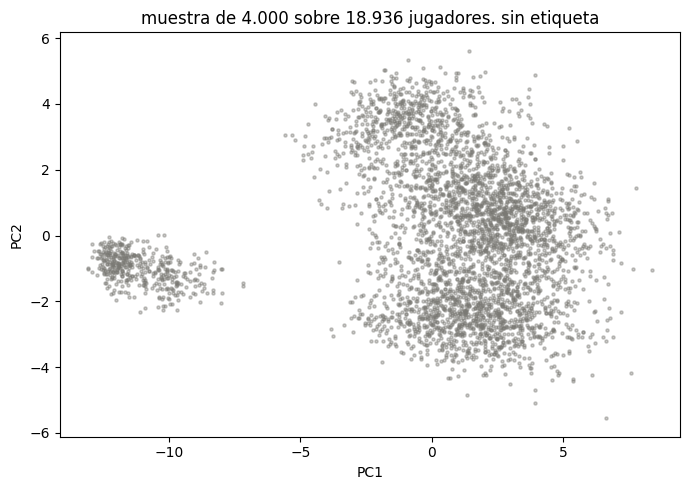

In [ ]:
def proyectar(p, datos):
    '''Las tres primeras coordenadas que devuelve un pipeline que termina en PCA, con el índice de las filas.'''
    return pd.DataFrame(p.transform(datos)[:, :3], columns=["PC1", "PC2", "PC3"], index=datos.index)

proy = proyectar(reducir, X)

muestra = proy.sample(4000, random_state=SEMILLA)
fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(muestra["PC1"], muestra["PC2"], s=5, alpha=0.4, color="#7a7974")
ax.set_xlabel("PC1"); ax.set_ylabel("PC2"); ax.set_title(f"muestra de 4.000 sobre {len(proy):,} jugadores, sin etiqueta".replace(",", "."))
plt.tight_layout()
plt.show()

Sin ninguna etiqueta, el gráfico ya muestra dos cosas: un grupo chico y apretado a la izquierda,
separado por un hueco del resto, y una nube grande que se estira de abajo a la derecha hacia
arriba, más densa en el medio. La pregunta de la unidad es qué son esas formas, y para contestarla
hay dos caminos: pedirle a un algoritmo que las corte (Parte 3), o mirar la etiqueta que tenemos
guardada. Lo segundo es trampa si se usa para aprender, y es legítimo si se usa para entender; la
diferencia está en decirlo.

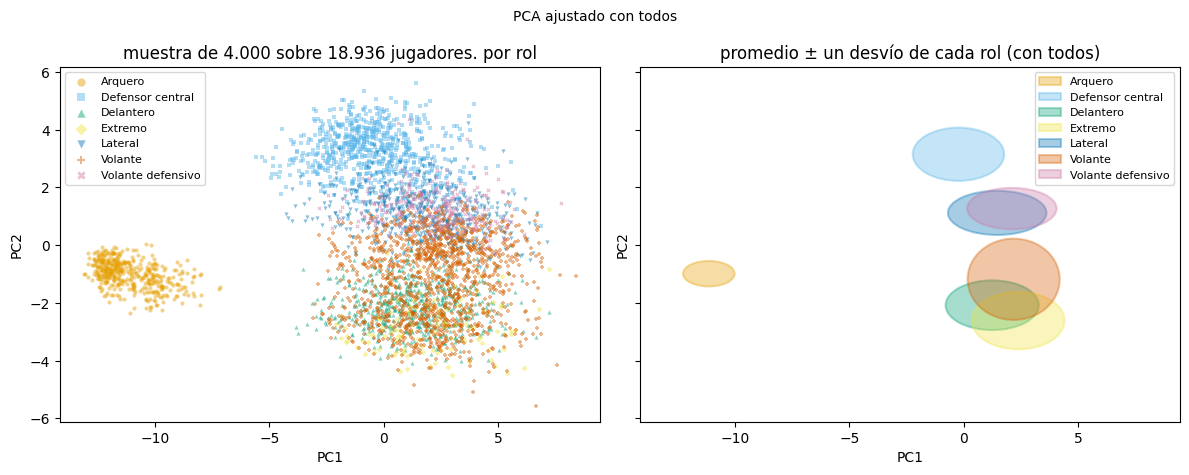

In [ ]:
from matplotlib.patches import Ellipse

# paleta de Okabe-Ito (distinguible con daltonismo) y un marcador distinto por rol
OKABE_ITO = ["#E69F00", "#56B4E9", "#009E73", "#F0E442", "#0072B2", "#D55E00", "#CC79A7"]
MARCADORES = ["o", "s", "^", "D", "v", "P", "X"]
estilo = {r: (c, m) for r, c, m in zip(sorted(rol.unique()), OKABE_ITO, MARCADORES)}

def elipse(ax, puntos, color, etiqueta):
    # una elipse centrada en el promedio del grupo, con semiejes de un desvío estándar en cada componente
    mx, my = puntos["PC1"].mean(), puntos["PC2"].mean()
    sx, sy = puntos["PC1"].std(),  puntos["PC2"].std()
    ax.add_patch(Ellipse((mx, my), 2 * sx, 2 * sy, facecolor=color, alpha=0.35, edgecolor=color, lw=1.5, label=etiqueta))

def graficar_2d(proy, titulo):
    '''La etiqueta, sólo para mirar: a la izquierda una muestra de puntos por rol, a la derecha una elipse por rol (promedio ± un desvío).'''
    roles = rol.loc[proy.index]
    puntos = proy.sample(min(4000, len(proy)), random_state=SEMILLA)
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.8), sharex=True, sharey=True)
    for r, grupo in puntos.groupby(roles.loc[puntos.index]):
        ax1.scatter(grupo["PC1"], grupo["PC2"], s=9, alpha=0.45, color=estilo[r][0], marker=estilo[r][1], label=r, linewidths=0)
    ax1.legend(markerscale=2, fontsize=8); ax1.set_title(f"muestra de {len(puntos):,} sobre {len(proy):,} jugadores, por rol".replace(",", "."))
    for r, grupo in proy.groupby(roles):
        elipse(ax2, grupo, estilo[r][0], r)
    ax2.legend(fontsize=8); ax2.set_title("promedio ± un desvío de cada rol (con todos)")
    for ax in (ax1, ax2):
        ax.set_xlabel("PC1"); ax.set_ylabel("PC2")
    fig.suptitle(titulo, fontsize=10)
    plt.tight_layout()
    plt.show()

graficar_2d(proy, "PCA ajustado con todos")

El grupo de la izquierda son los arqueros, todos, sin uno solo fuera: PC1 los separa sola. En la
nube grande, PC2 ordena de arriba a abajo: centrales arriba, laterales y volantes defensivos en el
medio, volantes abajo, extremos y delanteros bien abajo. Y de izquierda a derecha, PC1 ordena por
nivel: a la derecha están los que saben hacer de todo, sea cual sea su rol.

Las elipses de la derecha resumen lo mismo sin el ruido de los puntos: el centro de cada rol y
cuánto se desparrama, un desvío en cada eje. Los arqueros tienen la suya aparte; los otros seis se
**pisan**: la de los laterales se superpone con la de los volantes defensivos y la de los volantes,
y la de los extremos está casi adentro de la de los delanteros. Sólo los centrales tienen un centro
claramente propio.

Lo que no se ve son siete grupos: se ven dos bloques —arqueros y campo— y dentro del campo un
degradé defensa-ataque sin huecos. Un volante y un extremo no están separados por un vacío sino
por un matiz. Eso ya es una respuesta parcial a la pregunta de la clase, y la Parte 3 la pone a
prueba con algoritmos que no miran colores.

### 2.4 En tres ejes

PC3 es el 8 % de la varianza —físico contra movilidad— y en el gráfico de arriba no está. Con tres
componentes se pierde menos (81 % contra 73 %), y la pregunta es si esa tercera dirección separa
algo que las dos primeras mezclaban. Las mismas elipses, ahora elipsoides: centro en el promedio y
un desvío en cada eje. El gráfico **se gira con el mouse**; conviene girarlo hasta mirar cada par de
ejes de frente. Los arqueros se dejan afuera del dibujo porque quedan lejos a la izquierda y
aplastan la escala; ya se vieron.

In [ ]:
import plotly.graph_objects as go

def elipsoide(puntos, color, nombre, n=24):
    # la superficie de un elipsoide centrado en el promedio del grupo, con semiejes de un desvío en PC1, PC2 y PC3
    m = puntos[["PC1", "PC2", "PC3"]].mean().values; sd = puntos[["PC1", "PC2", "PC3"]].std().values
    u, v = np.meshgrid(np.linspace(0, 2 * np.pi, n), np.linspace(0, np.pi, n))
    return go.Surface(x=m[0] + sd[0] * np.cos(u) * np.sin(v), y=m[1] + sd[1] * np.sin(u) * np.sin(v), z=m[2] + sd[2] * np.cos(v),
                      surfacecolor=np.zeros_like(u), colorscale=[[0, color], [1, color]], showscale=False, opacity=0.45,
                      name=nombre, showlegend=True, hoverinfo="name")

def graficar_3d(proy, titulo):
    '''Los jugadores de campo como puntos (una muestra) y un elipsoide por rol; la etiqueta, sólo para mirar.'''
    roles = rol.loc[proy.index]
    puntos = proy[roles != "Arquero"].sample(3000, random_state=SEMILLA)
    fig = go.Figure()
    fig.add_trace(go.Scatter3d(x=puntos["PC1"], y=puntos["PC2"], z=puntos["PC3"], mode="markers",
                               marker=dict(size=1.5, color="#7a7974", opacity=0.25), name="jugadores de campo", hoverinfo="skip"))
    for r, grupo in proy.groupby(roles):
        if r != "Arquero":
            fig.add_trace(elipsoide(grupo, estilo[r][0], r))
    fig.update_layout(width=760, height=560, margin=dict(l=0, r=0, t=50, b=0),
                      title=f"{titulo}<br><sup>puntos: muestra de 3.000 sobre {(roles != 'Arquero').sum():,} jugadores de campo; elipsoides: con todos</sup>".replace(",", "."),
                      scene=dict(xaxis_title="PC1", yaxis_title="PC2", zaxis_title="PC3", aspectmode="cube"),
                      legend=dict(orientation="h", y=-0.02))
    fig.show()

graficar_3d(proy, "PCA ajustado con todos: promedio ± un desvío de cada rol de campo")

In [ ]:
# lo que se ve al girar, en números: la correlación entre las componentes (y con overall), sólo entre los jugadores de campo
de_campo = proy[rol != "Arquero"]
de_campo.corr().assign(overall=de_campo.corrwith(X.loc[de_campo.index, "overall"])).round(2)

,PC1,PC2,PC3,overall
PC1,1.00,-0.30,0.75,0.82
PC2,-0.30,1.00,0.08,0.03
PC3,0.75,0.08,1.00,0.84


Girando hasta mirar PC1 contra PC3, los puntos no forman una nube redonda sino una **diagonal**:
entre los jugadores de campo, PC1 y PC3 tienen correlación **0,75**. Y las dos se parecen al nivel:
la correlación con `overall` es 0,82 para PC1 y 0,84 para PC3. Mirado sólo desde los de campo, PC1
es el nivel, PC2 la posición en la cancha, y PC3… también el nivel.

No es un error de PCA: las componentes son perpendiculares —correlación cero— **sobre el conjunto
con el que se ajustaron**, que incluye a los 2.106 arqueros. PC1 se ajustó para separar arqueros de
jugadores de campo, y entre los de campo esa dirección queda medio vacía; lo que la llena es el
nivel, que se reparte entre PC1 y PC3. La tercera dimensión no agrega una dirección nueva: agrega
una que está torcida respecto de la primera.

Es una lección que conviene llevarse: **una proyección ajustada con unos datos describe mal a un
subconjunto de esos datos.** Si los arqueros no interesan, hay que sacarlos *antes* de ajustar, y
eso es un paso del pipeline, no un filtro en el gráfico. Es la Parte 4; antes, la Parte 3 pregunta
qué grupos encuentra un algoritmo con los arqueros adentro.

## Parte 3 — Clustering: dos definiciones de grupo

Agrupar es decidir quién va con quién sin que nadie diga cómo. Hay dos maneras de definir «grupo»,
y dan dos familias de algoritmos:

- **Por centros.** Un grupo es el conjunto de puntos más cercanos a un mismo centro. Hay que decir
  cuántos centros; el algoritmo los ubica. Es **k-means**.
- **Por densidad.** Un grupo es una zona donde los puntos están apretados, separada de otras por
  zonas vacías. No hay que decir cuántos; hay que decir qué es «apretado». Es **DBSCAN**.

Las dos se corren acá **sobre PC1 y PC2**, no sobre las 34 habilidades. Es una decisión del
pipeline, y se escribe: con dos componentes todo se puede dibujar, y el dibujo es el que va a decir
si el algoritmo encontró lo que se ve. Cuesta el 27 % de la varianza que no está en esas dos; en el
integrador, sobre las columnas originales o sobre más componentes, es el mismo pipeline con otro
`n_components`. Cada pipeline de esta parte es entonces: elegir y escalar, proyectar a dos
componentes, agrupar.

### 3.1 k-means

**k-means** parte de *k* centros al azar y repite dos pasos hasta que nada cambia: asigna cada
jugador al centro más cercano, y mueve cada centro al promedio de los jugadores que le tocaron.
Necesita que le digan *k*, y ahí está la decisión.

`KMeans` es un estimador que aprende los centros en `fit`, y después sabe hacer las dos cosas:
`predict` devuelve el grupo del centro más cercano, y `transform` devuelve las distancias a los
*k* centros. Sus parámetros aprendidos son `cluster_centers_`, `labels_` —el grupo de cada fila
con la que se ajustó— e `inertia_`; su hiperparámetro es `n_clusters`. La semilla fija los centros
iniciales, y `n_init=10` prueba diez arranques y se queda con el de menor inercia.

Para elegir *k*, dos medidas internas, las dos con fórmula corta y las dos con nombre prestado.

**La inercia** es lo que k-means minimiza: la suma, sobre todos los jugadores, de la distancia al
cuadrado entre cada uno y el centro de su grupo.

$$
\text{inercia} = \sum_{i} \lVert x_i - \mu_{g(i)} \rVert^{2}
$$

donde $x_i$ son las coordenadas del jugador $i$ (acá, PC1 y PC2), $g(i)$ el grupo que le tocó y
$\mu_{g}$ el centro del grupo $g$. El nombre viene de la física: el momento de inercia de un cuerpo
respecto de su centro de masa es $\sum m_i r_i^2$, masa por distancia al cuadrado; con un jugador por
partícula y masa 1, es la misma suma. La escuela francesa de análisis de datos, que trató a las
nubes de puntos como cuerpos, la llamó *inertie* y el nombre quedó. Siempre baja al agregar centros
—con tantos centros como jugadores es cero—, así que no se busca el mínimo sino el **codo**: el *k*
después del cual agregar uno más casi no ayuda. Con *k* = 1 el único centro es el promedio, y la
inercia es la varianza total. Ese valor va en el gráfico, porque sin él no se puede ver si *k* = 2
es un codo o no.

**El silhouette** se calcula por jugador y compara dos distancias medias:

$$
s(i) = \frac{b(i) - a(i)}{\max\{a(i),\, b(i)\}}
$$

donde $a(i)$ es la distancia media del jugador $i$ a los de **su** grupo, y $b(i)$ la distancia media
al grupo **más cercano que no es el suyo**. Si está bien adentro de su grupo, $a$ es chica y $b$
grande: $s$ se acerca a 1. Si está en el borde, $a \approx b$ y $s \approx 0$. Si quedó en el grupo
equivocado, $a > b$ y $s$ es negativo. Con *k* = 1 no existe: no hay otro grupo contra el que medir
$b$. El promedio de $s(i)$ sobre todos los jugadores es un número para comparar *k* distintos; **el
k con mayor silhouette es el que separa mejor.** Es más caro que la inercia —compara cada jugador
con todos los demás—, por eso se calcula sobre una muestra. El nombre lo puso Rousseeuw en 1987 por
el gráfico que propuso con él, que se ve en la sección 3.2.

**Elegir k como un paso del pipeline.** Si la regla es «el k con mayor silhouette», la regla se puede
escribir como estimador: en `fit` prueba cada *k*, mide, y se queda con el mejor. Así la decisión
queda adentro del objeto —en `k_`, con la tabla del barrido en `barrido_`— y no en un bucle aparte
que después hay que recordar. Quedan dos pipelines, y los dos se arman con la misma función
`agrupar`: con `k=None` elige solo; con un número, se le fuerza *k* y se escribe por qué.

k elegido: 2


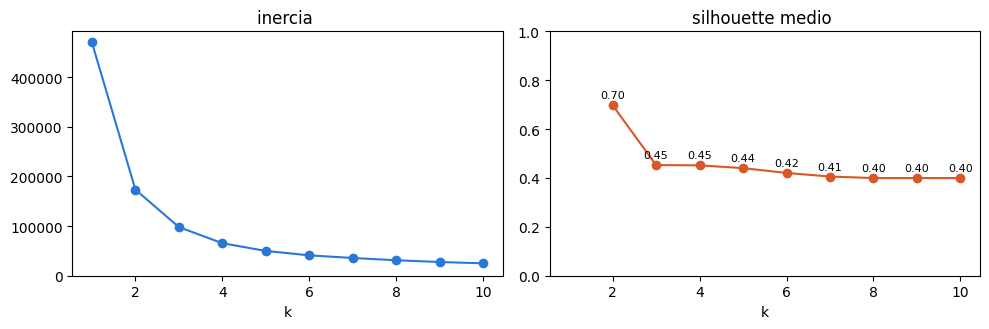

In [ ]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

class KMeansAuto(BaseEstimator, TransformerMixin):
    '''k-means que elige k solo: ajusta uno por cada k de ks y se queda con el de mayor silhouette medio.'''

    def __init__(self, ks=range(2, 11), muestra=5000):
        self.ks = ks
        self.muestra = muestra

    def fit(self, X, y=None):
        modelos, filas = {}, {1: {"inercia": ((X - X.mean(axis=0)) ** 2).sum(), "silhouette": np.nan}}   # k = 1: el centro es el promedio
        for k in self.ks:
            modelos[k] = KMeans(n_clusters=k, n_init=10, random_state=SEMILLA).fit(X)
            filas[k] = {"inercia": modelos[k].inertia_,
                        "silhouette": silhouette_score(X, modelos[k].labels_, sample_size=self.muestra, random_state=SEMILLA)}
        self.barrido_ = pd.DataFrame(filas).T.rename_axis("k")
        self.k_ = int(self.barrido_["silhouette"].idxmax())
        self.kmeans_ = modelos[self.k_]
        self.labels_, self.inertia_, self.cluster_centers_ = self.kmeans_.labels_, self.kmeans_.inertia_, self.kmeans_.cluster_centers_
        return self

    def predict(self, X):
        return self.kmeans_.predict(X)

    def transform(self, X):
        return self.kmeans_.transform(X)


def agrupar(k=None):
    '''El pipeline de agrupar: las 34 habilidades escaladas, dos componentes, y k-means. Con k=None elige k solo; con un número, se lo fuerza.'''
    kmeans = KMeansAuto() if k is None else KMeans(n_clusters=k, n_init=10, random_state=SEMILLA)
    return Pipeline([("habilidades", habilidades()),
                     ("pca",         PCA(n_components=2, random_state=SEMILLA)),
                     ("kmeans",      kmeans)])

def graficar_barrido(barrido, titulo=""):
    '''La inercia (con k = 1) y el silhouette medio (desde k = 2) de un barrido_.'''
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 3.4))
    ax1.plot(barrido.index, barrido["inercia"], marker="o", color="#2a78d6"); ax1.set_title(f"inercia {titulo}"); ax1.set_xlabel("k"); ax1.set_ylim(0)
    s = barrido["silhouette"].dropna()
    ax2.plot(s.index, s, marker="o", color="#d95926"); ax2.set_title(f"silhouette medio {titulo}"); ax2.set_xlabel("k"); ax2.set_ylim(0, 1); ax2.set_xlim(ax1.get_xlim())
    for k, v in s.items():
        ax2.annotate(f"{v:.2f}", (k, v), textcoords="offset points", xytext=(0, 5), ha="center", fontsize=8)
    plt.tight_layout()
    plt.show()

automatico = agrupar().fit(X)
print("k elegido:", automatico["kmeans"].k_)
graficar_barrido(automatico["kmeans"].barrido_)

Con *k* = 1 en el gráfico, el codo se ve: de 1 a 2 la inercia cae de 470.000 a 173.000, casi dos
tercios, y de 2 a 3 cae 75.000. Sin ese primer punto el gráfico empezaría en 2 y el codo estaría
disimulado, porque lo que hace a un codo es la caída *anterior*. El silhouette lo dice sin
ambigüedad: **0,70 con dos grupos**, y 0,45 o menos con cualquier otro valor; el paso eligió
**k = 2**. Dos grupos bien separados, y adentro de uno de ellos nada que un tercer centro recorte
limpiamente.

### 3.2 Lo que k = 2 encontró

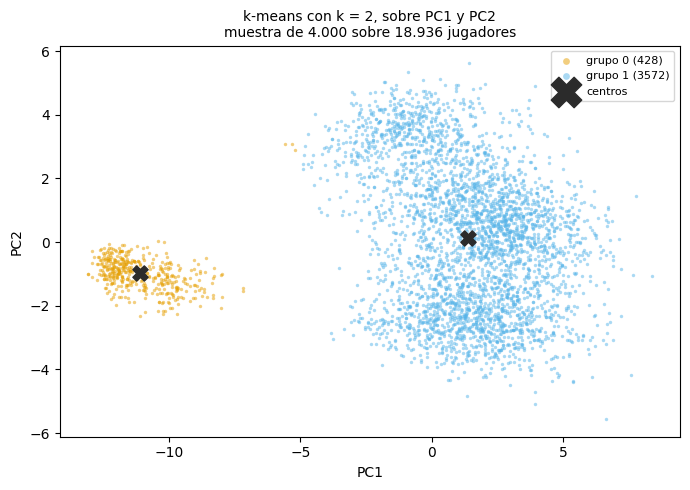

In [ ]:
def graficar_grupos(p, datos, titulo, muestra=4000):
    '''Los grupos de un pipeline de agrupar, sobre el plano PC1-PC2: una muestra de puntos coloreada por grupo (gris para el ruido) y, si hay, los centros.'''
    filas = p[:1].transform(datos).index if "sin_arqueros" in p.named_steps else datos.index   # las filas que llegan al último paso
    ultimo = p[-1]
    idx = filas.to_series().sample(min(muestra, len(filas)), random_state=SEMILLA).index
    if not hasattr(ultimo, "predict"):   # DBSCAN: la muestra, más todo el ruido, que es poco y es lo interesante
        etiquetas = pd.Series(ultimo.labels_, index=filas)
        idx = idx.union(etiquetas[etiquetas == -1].index)
    Z = p[:-1].transform(datos.loc[idx])
    g = ultimo.predict(Z) if hasattr(ultimo, "predict") else pd.Series(ultimo.labels_, index=filas).loc[idx].values
    fig, ax = plt.subplots(figsize=(7, 5))
    for grupo in sorted(set(g)):
        if grupo == -1:
            ax.scatter(Z[g == grupo, 0], Z[g == grupo, 1], s=28, marker="x", color="#2b2b2b", label=f"ruido (−1) ({(g == grupo).sum()})", zorder=4)
        else:
            ax.scatter(Z[g == grupo, 0], Z[g == grupo, 1], s=6, alpha=0.5, color=OKABE_ITO[grupo % 7], label=f"grupo {grupo} ({(g == grupo).sum()})", linewidths=0)
    if hasattr(ultimo, "cluster_centers_"):
        ax.scatter(ultimo.cluster_centers_[:, 0], ultimo.cluster_centers_[:, 1], marker="X", s=120, color="#2b2b2b", label="centros", zorder=5)
    ax.legend(fontsize=8, markerscale=2); ax.set_xlabel("PC1"); ax.set_ylabel("PC2")
    nota = "; el ruido, completo" if not hasattr(ultimo, "predict") else ""
    n_muestra, n_filas = f"{min(muestra, len(filas)):,}".replace(",", "."), f"{len(filas):,}".replace(",", ".")
    ax.set_title(f"{titulo}\nmuestra de {n_muestra} sobre {n_filas} jugadores{nota}", fontsize=10)
    plt.tight_layout()
    plt.show()

graficar_grupos(automatico, X, "k-means con k = 2, sobre PC1 y PC2")

In [ ]:
# el grupo que le tocó a cada jugador, aprendido en fit; el perfil de cada grupo en cuatro habilidades, sin mirar ninguna etiqueta
etiqueta_2 = automatico["kmeans"].labels_
X.assign(grupo=etiqueta_2).groupby("grupo")[["goalkeeping_diving", "goalkeeping_reflexes", "movement_sprint_speed", "attacking_finishing"]].mean().round(1).assign(jugadores=pd.Series(etiqueta_2).value_counts().sort_index().values)

,goalkeeping_diving,goalkeeping_reflexes,movement_sprint_speed,attacking_finishing,jugadores
grupo,,,,,
0,64.3,65.1,34.5,9.8,2111
1,10.2,10.1,68.8,51.4,16825


In [ ]:
# la etiqueta, sólo para confirmar lo que el perfil ya dijo
pd.crosstab(pd.Series(etiqueta_2, index=X.index, name="grupo"), rol)

best_position,Arquero,Defensor central,Delantero,Extremo,Lateral,Volante,Volante defensivo
grupo,,,,,,,
0,2106,5,0,0,0,0,0
1,0,3764,2681,499,2439,6153,1289


En el plano se ve lo que k-means hizo: dos centros, uno en la nube chica de la izquierda y otro en
el medio de la grande, y cada jugador con el más cercano. Un grupo de 2.111 jugadores con sesenta y
pico en atajadas y reflejos, diez en definición y treinta y cuatro de velocidad; otro de 16.825 con
los números al revés. No hace falta la etiqueta para ponerle nombre: son los arqueros. La tabla lo
confirma —los 2.106 arqueros, ninguno afuera— y agrega un detalle que vale la pena: **cinco
defensores centrales** cayeron con ellos. Son jugadores de 48 a 50 de overall, tan bajos en todo
que en PC1, que mide nivel, quedan más cerca del centro de los arqueros que del de los jugadores de
campo. k-means no se equivocó: hizo lo que la distancia le dijo. Es la primera muestra de que
agrupar por centros corta por donde pasa la distancia, no por donde pasa el sentido.

**El gráfico de las siluetas.** De dónde sale el silhouette lo muestra el gráfico de Rousseeuw, que
se lee así: cada jugador es una línea horizontal cuyo largo es su $s(i)$; las líneas se apilan, un
grupo debajo del otro, y adentro de cada grupo van ordenadas de la más larga a la más corta. Así
cada grupo dibuja una figura —la *silueta*— cuya **altura** es cuántos jugadores tiene y cuyo
**ancho** dice qué tan adentro de su grupo están: un grupo compacto y lejos de los demás es un
bloque ancho y parejo; uno que se deshilacha termina en una punta que llega a cero, o cruza a los
negativos. La línea punteada es el promedio, el número que se usó para elegir *k*.

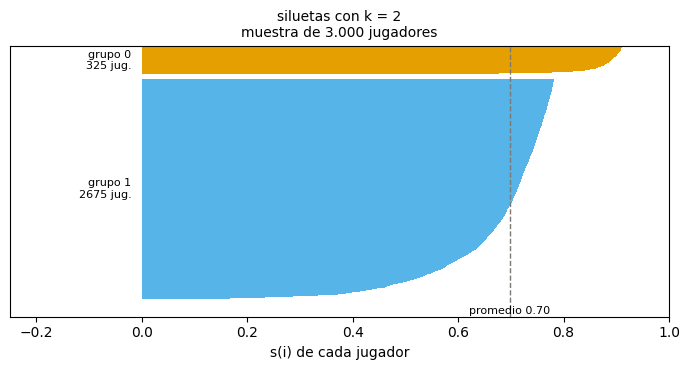

In [ ]:
from sklearn.metrics import silhouette_samples

def graficar_siluetas(p, datos, titulo=""):
    '''El gráfico de Rousseeuw: cada jugador es una línea de largo s(i), apiladas por grupo y ordenadas; sobre una muestra.
       Las coordenadas salen del pipeline sin su último paso; el grupo, de predict del último.'''
    idx = datos.sample(3000, random_state=SEMILLA).index
    Z = p[:-1].transform(datos.loc[idx]); g = p["kmeans"].predict(Z)
    s = silhouette_samples(Z, g)
    fig, ax = plt.subplots(figsize=(7, 3.8)); y0 = 0
    for grupo in sorted(set(g)):
        valores = np.sort(s[g == grupo])[::-1]
        y = np.arange(y0, y0 + len(valores))
        ax.barh(y, valores, height=1, color=OKABE_ITO[grupo % 7])
        ax.text(-0.02, y0 + len(valores) / 2, f"grupo {grupo}\n{len(valores)} jug.", ha="right", va="center", fontsize=8)
        y0 += len(valores) + 60
    ax.axvline(s.mean(), color="#7a7974", ls="--", lw=1); ax.annotate(f"promedio {s.mean():.2f}", (s.mean(), y0 + 20), fontsize=8, ha="center", va="top")
    ax.set_xlabel("s(i) de cada jugador"); ax.set_yticks([]); ax.set_xlim(-0.25, 1); ax.set_ylim(-20, y0 + 150)
    ax.set_title(f"{titulo}\nmuestra de {len(s):,} jugadores".replace(",", "."), fontsize=10)   # el título no lleva comas
    ax.invert_yaxis()
    plt.tight_layout()
    plt.show()

graficar_siluetas(automatico, X, "siluetas con k = 2")

Se leen dos siluetas. La de arriba, el grupo 0, es baja —son 2.111 de 18.936, unos 325 en la
muestra de 3.000— y ancha: casi todos los arqueros tienen $s(i)$ arriba de 0,7, porque cualquier arquero
está mucho más cerca de los demás arqueros que de cualquier jugador de campo. La de abajo, el grupo
1, es alta y empieza igual de ancha, pero se deshilacha: una cola de jugadores de campo con $s(i)$
que baja hasta cero, los que están en la punta derecha de la nube, tan lejos de su centro como
podrían estarlo del otro. Ninguna cruza a los negativos: nadie quedó en el grupo equivocado. El
0,70 es el promedio de todo eso, y la forma de las siluetas dice más que el número: una división
limpia, con un grupo grande que es ancho por dentro.

### 3.3 DBSCAN

La otra definición. Para **DBSCAN** un grupo es una zona *densa*: cada punto tiene al menos
`min_samples` vecinos a distancia menor que `eps`, y los grupos son las zonas densas que están
conectadas entre sí. No hay que decirle cuántos grupos hay: los encuentra; y lo que no está cerca de
ninguna zona densa queda afuera, como **ruido**, con etiqueta −1. Donde k-means ve «el centro más
cercano», DBSCAN ve «¿hay un hueco en el medio?».

`DBSCAN` es un estimador con `fit`, `labels_` y `core_sample_indices_` (los puntos núcleo, los que
tienen vecinos suficientes); **no tiene `predict`**, porque no aprende centros ni fronteras, sólo
etiqueta los puntos con los que se ajustó. Su hiperparámetro difícil es `eps`, y la forma usual de
elegirlo es mirar a qué distancia está el `min_samples`-ésimo vecino de cada jugador: la mayoría
está adentro de una nube y lo tiene cerca; los pocos que lo tienen lejos son los que están en los
huecos. Es el equivalente del codo de la inercia.

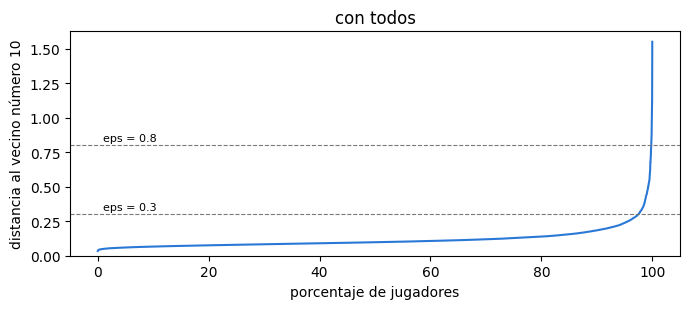

,grupos,ruido,tamaños
eps,,,
0.1,121,5587,"7.952, 1.560, 1.252"
0.2,17,854,"15.891, 2.026, 34"
0.3,3,228,"16.627, 2.074, 7"
0.5,2,51,"16.786, 2.099"
0.8,2,8,"16.823, 2.105"
1.2,2,0,"16.830, 2.106"


In [ ]:
from sklearn.cluster import DBSCAN
from sklearn.neighbors import NearestNeighbors

MIN_VECINOS = 10

def densidad(eps):
    '''El pipeline de agrupar por densidad: las 34 habilidades escaladas, dos componentes, y DBSCAN.'''
    return Pipeline([("habilidades", habilidades()),
                     ("pca",         PCA(n_components=2, random_state=SEMILLA)),
                     ("dbscan",      DBSCAN(eps=eps, min_samples=MIN_VECINOS))])

def graficar_distancias(Z, candidatos, titulo=""):
    '''La distancia de cada punto a su vecino número MIN_VECINOS, ordenada: donde se dispara, empieza el hueco.'''
    d = np.sort(NearestNeighbors(n_neighbors=MIN_VECINOS).fit(Z).kneighbors(Z)[0][:, -1])
    fig, ax = plt.subplots(figsize=(7, 3.2))
    ax.plot(np.linspace(0, 100, len(d)), d, color="#2a78d6")
    for eps in candidatos:
        ax.axhline(eps, color="#7a7974", lw=0.8, ls="--"); ax.annotate(f"eps = {eps}", (1, eps), textcoords="offset points", xytext=(0, 3), fontsize=8)
    ax.set_xlabel("porcentaje de jugadores"); ax.set_ylabel(f"distancia al vecino número {MIN_VECINOS}"); ax.set_ylim(0); ax.set_title(titulo)
    plt.tight_layout()
    plt.show()

def barrido_eps(fabricar, datos, candidatos):
    '''Qué encuentra DBSCAN para cada eps: cuántos grupos, de qué tamaño, cuánto ruido.'''
    filas = {}
    for eps in candidatos:
        etiquetas = pd.Series(fabricar(eps).fit(datos)["dbscan"].labels_)
        tamaños = etiquetas[etiquetas >= 0].value_counts().sort_values(ascending=False)
        filas[eps] = {"grupos": len(tamaños), "ruido": int((etiquetas == -1).sum()), "tamaños": ", ".join(f"{t:,}".replace(",", ".") for t in tamaños.head(3))}
    return pd.DataFrame(filas).T.rename_axis("eps")

graficar_distancias(densidad(1)[:-1].fit_transform(X), [0.3, 0.8], "con todos")
barrido_eps(densidad, X, [0.1, 0.2, 0.3, 0.5, 0.8, 1.2])

La curva es plana hasta el 95 % de los jugadores —todos tienen a su décimo vecino a menos de
0,25— y sube en punta al final: los que están aislados. Con `eps` chico (0,1) la nube se parte en
121 pedazos y un tercio es ruido: en ese radio no caben diez vecinos salvo en lo más denso. Con
`eps` entre **0,5 y 1,2** la respuesta es siempre la misma: **dos grupos**, uno de 2.100 y uno de
16.800, y un puñado de ruido que se achica hasta desaparecer. Nadie le dijo dos. Y adentro del grupo
grande no aparece un tercer grupo con ningún `eps`: la nube de campo es un degradé sin huecos, dicho
por un algoritmo que sólo busca huecos. Se toma `eps = 0,8`, donde el ruido ya son ocho jugadores,
y se escribe que es una elección.

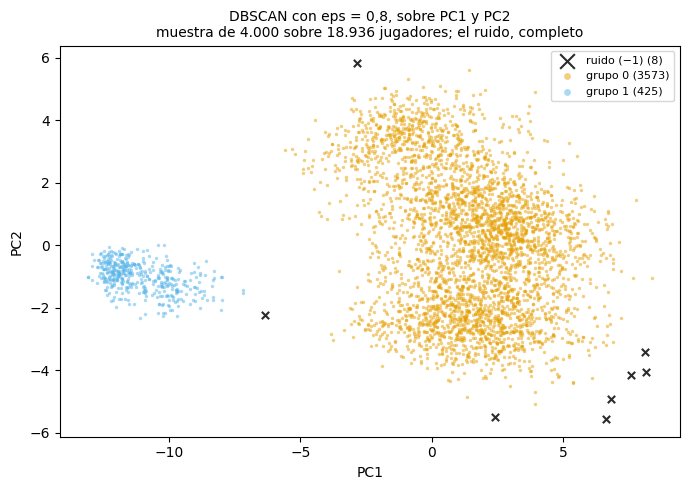

In [ ]:
por_densidad = densidad(0.8).fit(X)
graficar_grupos(por_densidad, X, "DBSCAN con eps = 0,8, sobre PC1 y PC2")

In [ ]:
# el perfil de cada grupo que DBSCAN encontró, sin mirar ninguna etiqueta; −1 es el ruido
etiqueta_db = pd.Series(por_densidad["dbscan"].labels_, index=X.index, name="grupo")
X.groupby(etiqueta_db)[["goalkeeping_diving", "goalkeeping_reflexes", "movement_sprint_speed", "attacking_finishing", "overall"]].mean().round(1).assign(jugadores=etiqueta_db.value_counts().sort_index().values)

,goalkeeping_diving,goalkeeping_reflexes,movement_sprint_speed,attacking_finishing,overall,jugadores
grupo,,,,,,
-1,17.8,17.9,73.9,67.1,82.8,8
0,10.2,10.2,68.8,51.4,65.9,16823
1,64.4,65.3,34.4,9.8,64.1,2105


In [ ]:
# los del ruido, con nombre: los que no están cerca de nadie
df.loc[etiqueta_db[etiqueta_db == -1].index, ["short_name", "club_name", "overall", "goalkeeping_diving", "attacking_finishing", "movement_sprint_speed"]].assign(rol=rol)

,short_name,club_name,overall,goalkeeping_diving,attacking_finishing,movement_sprint_speed,rol
2526,D. Batth,Derby County,69,11,20,35,Defensor central
2900,O. Dembélé,Paris Saint-Germain,90,6,90,89,Delantero
5058,P. Dybala,Roma,85,5,85,76,Volante
6189,L. Messi,Inter Miami,86,6,84,71,Volante
7745,K. Mbappé,Real Madrid,91,13,94,96,Delantero
7749,Lamine Yamal,FC Barcelona,89,9,84,84,Volante
11675,Ederson,Fenerbahçe SK,83,80,14,63,Arquero
15340,B. Boutobba,Al Najma SC,69,12,66,77,Volante


Los mismos dos grupos que k-means, con una diferencia y un regalo. La diferencia: el grupo de
arqueros tiene 2.105, no 2.111; los cinco centrales flojos que k-means mandó con los arqueros acá
están con los de campo, porque DBSCAN no mide distancia a un centro sino si hay un hueco en el
medio, y entre ellos y la nube de campo no lo hay. El regalo son **los ocho del ruido**, las cruces del
gráfico (la muestra es de 4.000, pero el ruido se dibuja completo): el algoritmo dice que no están cerca de nadie, y son Mbappé, Dembélé, Lamine Yamal, Messi, Dybala…
los que están en la punta derecha de PC1, donde el nivel es tan alto que no hay diez jugadores a
0,8 de distancia. Y Ederson, el único arquero que no está con los arqueros: 80 de atajadas y 63
de velocidad, un arquero que juega con los pies, a mitad de camino entre las dos nubes. El ruido
de DBSCAN no es basura: es la lista de los que no se parecen a nadie, y suele valer una mirada.

### 3.4 Dos definiciones, una respuesta

Dos algoritmos, dos definiciones de grupo, y la misma respuesta: los arqueros son un grupo y el
resto es uno solo. Lo que cambia es el camino, y conviene tener las diferencias a mano:

| | k-means | DBSCAN |
|---|---|---|
| un grupo es | los puntos más cercanos a un centro | una zona densa separada por zonas vacías |
| hay que decirle | *k* | `eps` y `min_samples` |
| cómo se elige | silhouette (o el codo de la inercia) | la curva de la distancia al vecino |
| forma de los grupos | convexa: corta el plano en celdas alrededor de los centros | cualquiera: sigue la densidad |
| ruido | no existe; todo jugador tiene un centro | sí: lo que no está en una zona densa queda afuera |
| filas nuevas | `predict`: el centro más cercano | no tiene; hay que agregar la regla a mano |
| cuándo falla | grupos de forma rara o de tamaños muy distintos | densidades muy distintas entre grupos; muchas dimensiones |

k-means puso los cinco centrales flojos con los arqueros porque eso dicta la distancia a los
centros; DBSCAN los dejó en el campo porque no hay un hueco entre ellos y el resto, y a cambio sacó
del juego a los ocho que no tienen vecinos. Ninguno de los dos está equivocado: respondieron
preguntas distintas. Y en lo que importa coinciden, incluido lo que **no** encontraron: adentro de
los jugadores de campo, ni un tercer centro que recorte bien ni un hueco de densidad. La Parte 4
saca a los arqueros y vuelve a preguntar.

## Parte 4 — Sin los arqueros

Las dos definiciones de grupo coinciden en que los arqueros son un grupo aparte, y en que adentro
del resto no hay un corte limpio. La pregunta interesante empieza cuando se los saca: ¿qué queda
entre los jugadores de campo? Y la sección 2.4 ya dijo cómo hay que sacarlos: **antes de ajustar**,
como un paso del pipeline, para que el escalado, PCA y los algoritmos de agrupar aprendan sin
ellos. Esta parte hace eso y mira, paso por paso, qué cambia.

### 4.1 El paso que los saca

La decisión: los arqueros se sacan **sin mirar la etiqueta**, por lo que los datos dicen de ellos.
De los dos algoritmos de la Parte 3, el conveniente para esto es k-means con *k* = 2, por una razón
de forma: tiene `predict`, así que el paso puede decidir sobre cualquier fila que reciba, no sólo
sobre las que vio en `fit`. DBSCAN encontró lo mismo, pero sin `predict` habría que agregarle la
regla a mano. El paso corre `agrupar(2)` en `fit`, se queda con el número del grupo de mayor
`goalkeeping_diving` —ese es el de arqueros, con etiqueta o sin ella—, y en `transform` devuelve las
filas que `predict` no manda a ese grupo.

Hay que decir lo que tiene de raro. Los transformadores de scikit-learn cambian columnas, no filas:
el `Pipeline` no lo prohíbe, pero tampoco lo espera, y por eso lo que un paso posterior aprende
sobre «cada fila» —`labels_`— ya no se corresponde una a una con `X` sino con lo que salió de este
paso. Para alinear se le pide al paso las filas que dejó pasar. Sirve para explorar, que es lo que
se hace hoy; en un pipeline que predice fila a fila (la Parte 5), este paso no va.

In [ ]:
from sklearn.base import clone

class SinArqueros(BaseEstimator, TransformerMixin):
    '''Saca las filas del grupo que k-means con k = 2 identifica como arqueros: el de mayor goalkeeping_diving promedio.'''

    def fit(self, X, y=None):
        self.dos_grupos_ = agrupar(2).fit(X)
        self.grupo_arqueros_ = int(X.assign(g=self.dos_grupos_.predict(X)).groupby("g")["goalkeeping_diving"].mean().idxmax())
        return self

    def transform(self, X):
        return X[self.dos_grupos_.predict(X) != self.grupo_arqueros_]


def sin_arqueros(p):
    '''El mismo pipeline p, con el paso que saca a los arqueros adelante.'''
    return Pipeline([("sin_arqueros", SinArqueros()), *clone(p).steps])

# el paso, solo, para ver qué deja pasar
paso = SinArqueros().fit(X)
campo = paso.transform(X)
rol_campo = rol.loc[campo.index]
pd.Series({"grupo identificado como arqueros": paso.grupo_arqueros_, "jugadores que entran": len(X), "jugadores que salen": len(campo)})

grupo identificado como arqueros        0
jugadores que entran                18936
jugadores que salen                 16825
dtype: int64

In [ ]:
# la etiqueta, sólo para mirar: qué sacó el paso
pd.crosstab(pd.Series(np.where(X.index.isin(campo.index), "queda", "sale"), index=X.index, name=""), rol)

best_position,Arquero,Defensor central,Delantero,Extremo,Lateral,Volante,Volante defensivo
,,,,,,,
queda,0,3764,2681,499,2439,6153,1289
sale,2106,5,0,0,0,0,0


El paso saca 2.111: los 2.106 arqueros y los cinco centrales flojos que k-means puso con ellos en
3.2, porque el paso *es* ese k-means. Es un costo del método elegido y se declara: con DBSCAN
habrían salido 2.105 y Ederson se habría quedado. Son cinco jugadores en dieciséis mil, y no
cambian nada de lo que sigue; pero la regla del notebook es que cada cambio se explique por un paso,
y este paso explica esos cinco.

### 4.2 Lo que cambia en PCA

Lo primero que cambia es el escalado, porque `StandardScaler` ahora aprende medias y desvíos sin
los arqueros:

In [ ]:
# el escalado, con y sin el paso: las cinco columnas de arquero, antes y después
reducir_campo = sin_arqueros(reducir).fit(X)
DE_ARQUERO = [c for c in DETALLADAS if c.startswith("goalkeeping_")]
pd.DataFrame({"media con todos":   pd.Series(reducir["habilidades"].named_transformers_["escalar"].mean_,        index=DETALLADAS),
              "desvío con todos":  pd.Series(reducir["habilidades"].named_transformers_["escalar"].scale_,       index=DETALLADAS),
              "media sin arqueros":  pd.Series(reducir_campo["habilidades"].named_transformers_["escalar"].mean_,  index=DETALLADAS),
              "desvío sin arqueros": pd.Series(reducir_campo["habilidades"].named_transformers_["escalar"].scale_, index=DETALLADAS)}).loc[DE_ARQUERO].round(1)

,media con todos,desvío con todos,media sin arqueros,desvío sin arqueros
goalkeeping_diving,16.2,17.5,10.2,3.0
goalkeeping_handling,16.0,16.9,10.2,3.0
goalkeeping_kicking,15.9,16.7,10.2,3.0
goalkeeping_positioning,16.1,17.1,10.2,3.0
goalkeeping_reflexes,16.3,17.8,10.1,3.0


Los `mean_` y `scale_` son los parámetros aprendidos del escalador, leídos de cada pipeline. Sin
arqueros, las cinco habilidades de arquero pasan de desvío 17 a desvío **3**: todos los de campo
tienen diez y pico, y el escalador, que no sabe que son columnas irrelevantes, las estira para que
tengan desvío 1 como las demás. Un jugador con 13 de atajadas queda un desvío entero arriba de uno
con 10. Es ruido amplificado, y es la consecuencia directa de que escalar esté *después* de sacar
filas; sacarlas del escalado sería otra decisión del pipeline, que acá no se toma, y se verifica
abajo que no pesan.

Lo segundo que cambia es PCA, que ahora busca direcciones entre jugadores que se parecen más entre
sí:

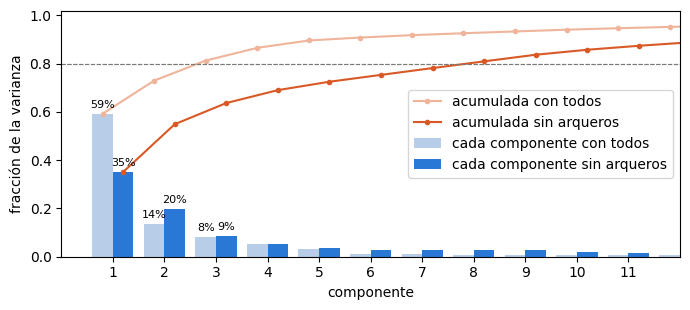

In [ ]:
fig, ax = plt.subplots(figsize=(7, 3.2))
graficar_varianza(ax, reducir["pca"],       "#b8cde8", "#f0b49b", "con todos",    corrimiento=-0.2, ancho=0.4)
graficar_varianza(ax, reducir_campo["pca"], "#2a78d6", "#d95926", "sin arqueros", corrimiento=+0.2, ancho=0.4)
ax.set_xlim(0, 12); ax.set_xticks(range(1, 12))   # las primeras once alcanzan para ver la diferencia
plt.tight_layout()
plt.show()

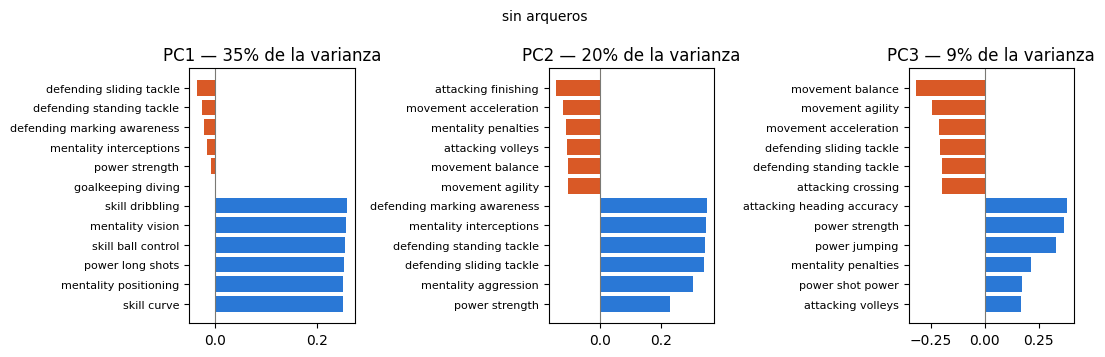

In [ ]:
graficar_cargas(reducir_campo["pca"], "sin arqueros")

La varianza se reparte distinto: la primera componente baja del 59 % al **35 %**, porque la
dirección arquero-contra-campo ya no existe; la segunda sube del 14 % al 20 %; con tres se explica el
64 % en vez del 81 %, y para llegar al 80 % hacen falta ocho componentes en vez de tres. No es que
los datos se hayan vuelto más complicados: es que la mitad de la varianza anterior era la distancia
entre dos deportes, y sin ella lo que queda es el matiz entre jugadores del mismo deporte.

Las recetas también cambian, y las cinco habilidades de arquero desaparecen de todas (su carga
máxima en las tres primeras es 0,03: el ruido amplificado no pesa):

- **PC1** ya no tiene lado negativo: es gambeta, visión, control, tiro de lejos, todo con el mismo
  signo. Es el **nivel técnico**, y su correlación con `overall` es 0,71.
- **PC2** es el eje **defensa contra ataque** de antes, más limpio: marca, intercepción y entrada
  contra definición y aceleración.
- **PC3** opone cabezazo, fuerza y salto a equilibrio, agilidad y aceleración: **físico contra
  movilidad**, también como antes.

En dos ejes, el mismo dibujo de 2.3 con la proyección nueva:

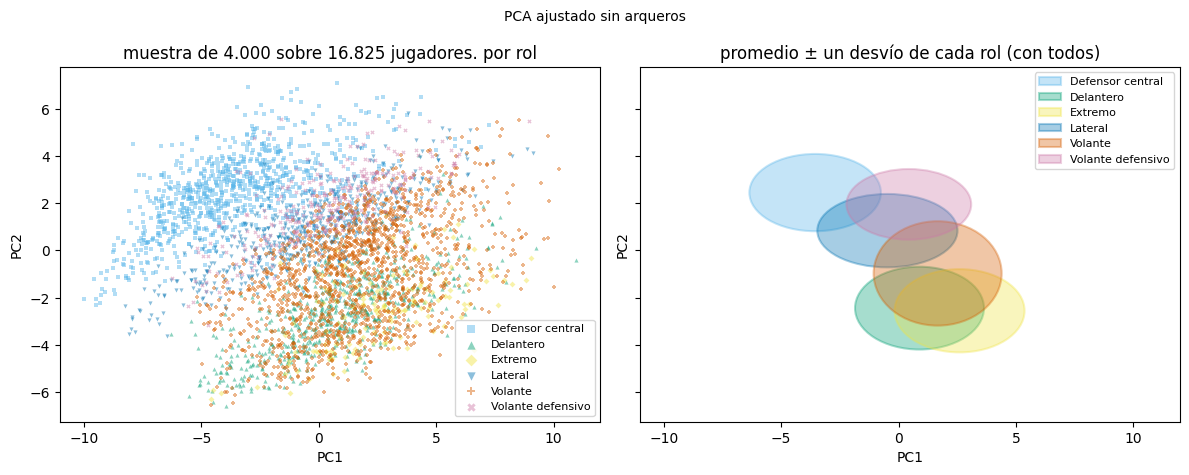

In [ ]:
proy_campo = proyectar(reducir_campo, campo)
graficar_2d(proy_campo, "PCA ajustado sin arqueros")

Sin la dirección arquero-contra-campo, la nube ocupa el plano entero en vez de estar apretada a la
derecha, y el degradé de 2.3 se abre: los centrales a la izquierda y arriba, los delanteros y
extremos a la derecha y abajo, laterales y volantes defensivos en el medio. Las elipses siguen
pisándose —no aparecieron huecos, porque no los hay—, pero ahora PC1 ordena de centrales (menos
técnica) a extremos (más técnica), no de malos a buenos: el nivel se repartió entre las dos
componentes en vez de llevarse una sola. Y la pregunta de la sección 2.4 vuelve: ¿la tercera
dimensión separa algo ahora?

In [ ]:
graficar_3d(proy_campo, "PCA ajustado sin arqueros: promedio ± un desvío de cada rol")

In [ ]:
# lo que el gráfico no deja leer con precisión: la correlación entre componentes (y con overall), y el centro de cada rol en PC3
display(proy_campo.corr().assign(overall=proy_campo.corrwith(campo["overall"])).round(2))
proy_campo.groupby(rol_campo)["PC3"].agg(["mean", "std"]).round(2).rename(columns={"mean": "PC3 promedio", "std": "PC3 desvío"}).T

,PC1,PC2,PC3,overall
PC1,1.0,-0.0,0.0,0.71
PC2,-0.0,1.0,0.0,0.53
PC3,0.0,0.0,1.0,0.14


best_position,Defensor central,Delantero,Extremo,Lateral,Volante,Volante defensivo
PC3 promedio,0.60,2.63,-0.25,-1.48,-0.83,-0.37
PC3 desvío,0.99,1.41,1.16,0.95,1.10,1.01


Ahora las tres componentes tienen correlación cero entre los jugadores de campo, porque se
ajustaron con ellos; al girar no hay diagonal. Y PC3 **separa algo que antes no separaba**: los
delanteros están en +2,6 y los laterales en −1,5, con los demás roles en el medio. Es el eje físico
—cabezazo, fuerza, salto— y los delanteros de área se van para un lado mientras los laterales y
volantes, ágiles, se van para el otro. En la sección 2.4 ese eje estaba ocupado por el nivel; sin
arqueros queda libre para medir lo que su receta dice.

Es el mismo dato con un paso más en el pipeline, y todo lo que cambió se explica por ese paso: el
escalado, porque aprende sin arqueros; la varianza, porque la dirección más grande desapareció; la
tercera componente, porque dejó de cargar con el nivel. Nada cambió por arte de magia.

### 4.3 Lo que cambia en k-means

El pipeline automático de 3.1 con el paso adelante. Proyecta a las dos componentes **nuevas**, las
de 4.2, porque PCA también está después del paso y aprende sin arqueros.

k elegido: 3


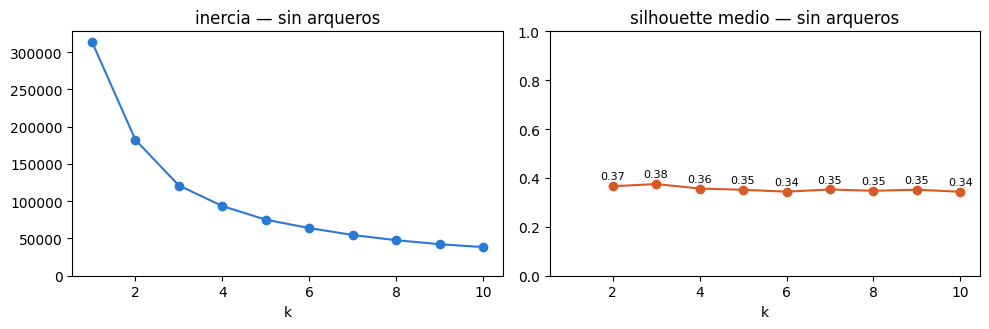

In [ ]:
automatico_campo = sin_arqueros(agrupar()).fit(X)
print("k elegido:", automatico_campo["kmeans"].k_)
graficar_barrido(automatico_campo["kmeans"].barrido_, "— sin arqueros")

Sin los arqueros, la señal fuerte desapareció: el silhouette es **0,37 con k = 2, 0,38 con k = 3**,
y entre 0,34 y 0,36 con todos los demás; el paso automático eligió 3, por una centésima. La
inercia no tiene codo: de 1 a 2 cae menos de la mitad, y después baja en una curva suave. Es la
forma que tienen estas medidas de decir que la nube de los jugadores de campo no tiene grupos
nítidos, sino el degradé que se vio en 4.2. Con 0,70 el silhouette decía «dos bloques»; con 0,38
dice «se puede cortar en tres, y en cuatro, y da casi lo mismo».

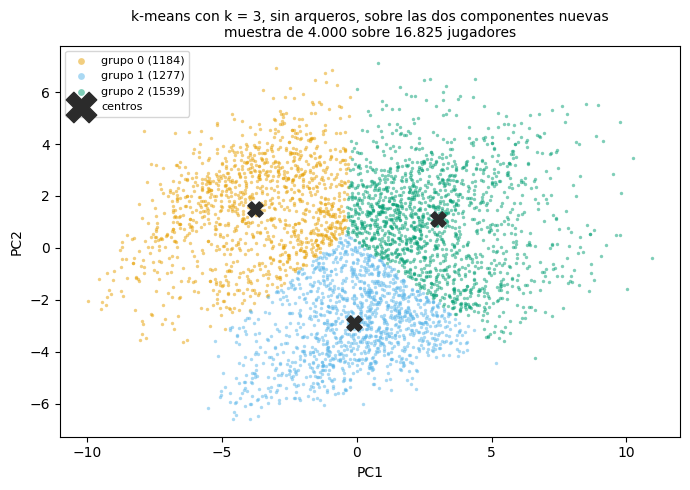

In [ ]:
K = automatico_campo["kmeans"].k_
grupos = pd.Series(automatico_campo["kmeans"].labels_, index=campo.index, name="grupo")   # labels_ sigue el orden de las filas que dejó pasar el primer paso
graficar_grupos(automatico_campo, X, f"k-means con k = {K}, sin arqueros, sobre las dos componentes nuevas")

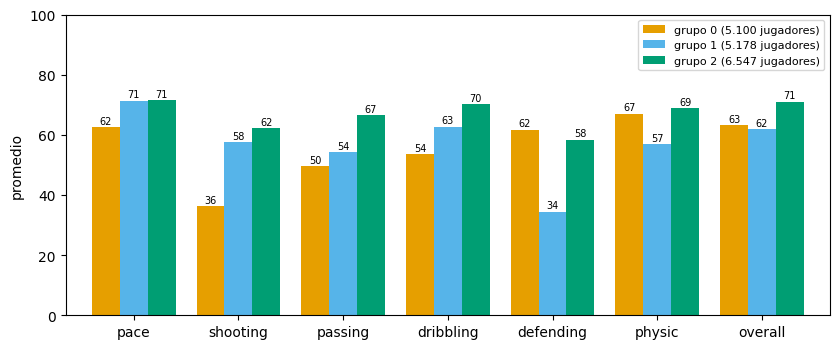

In [ ]:
# el perfil de cada grupo: las seis habilidades resumen y el overall, promedio por grupo (sin etiqueta)
RESUMEN = ["pace", "shooting", "passing", "dribbling", "defending", "physic", "overall"]
perfil = campo[RESUMEN].groupby(grupos).mean()
fig, ax = plt.subplots(figsize=(8.5, 3.6))
perfil.T.plot(kind="bar", ax=ax, width=0.8, color=OKABE_ITO[:len(perfil)])
for barras in ax.containers:
    ax.bar_label(barras, fmt="%.0f", fontsize=7, padding=1)
ax.set_ylabel("promedio"); ax.set_ylim(0, 100); ax.set_xticklabels(perfil.columns, rotation=0)
ax.legend([f"grupo {g} ({n:,} jugadores)".replace(",", ".") for g, n in grupos.value_counts().sort_index().items()], fontsize=8)
plt.tight_layout()
plt.show()

In [ ]:
# la etiqueta, para mirar: de cada rol, qué fracción cayó en cada grupo
pd.crosstab(rol_campo, grupos, normalize="index").round(2)

grupo,0,1,2
best_position,,,
Defensor central,0.87,0.00,0.13
Delantero,0.00,0.71,0.28
Extremo,0.00,0.58,0.42
Lateral,0.44,0.08,0.48
Volante,0.05,0.45,0.51
Volante defensivo,0.36,0.01,0.63


El plano lo muestra sin vueltas: tres centros sobre una nube continua, y **tres celdas** que se
tocan en línea recta. k-means corta el plano en regiones alrededor de los centros —siempre lo hace,
haya grupos o no—, y acá las fronteras pasan por el medio de donde hay jugadores, no por huecos.

Los tres grupos tienen perfil igual, y uno de ellos no es el que se esperaba:

- **Grupo 0**: defending 62, shooting 36. Defensores.
- **Grupo 1**: defending 34, shooting 58, pace 71. Atacantes.
- **Grupo 2**: alto en todo —passing 67, dribbling 70, physic 69— y, sobre todo, **overall 71
  contra 63 y 62** de los otros dos. No es un rol: son los jugadores buenos, de cualquier rol.

Es lo que PC1 anticipaba: la primera componente de los de campo es el nivel técnico, y un corte por
centros sobre ese plano corta por nivel antes que por puesto. La tabla lee cada rol: el 87 % de los
centrales cayó en el grupo 0 y el 71 % de los delanteros en el 1, que son los dos roles más puros.
Los laterales se reparten mitad y mitad entre «defensores» y «buenos»; los volantes, mitad entre
«atacantes» y «buenos»; los volantes defensivos van mayormente al grupo 2. Ningún rol del medio
queda en un solo grupo, y el grupo 2 se lleva una parte de todos: es el nivel cruzando los roles.

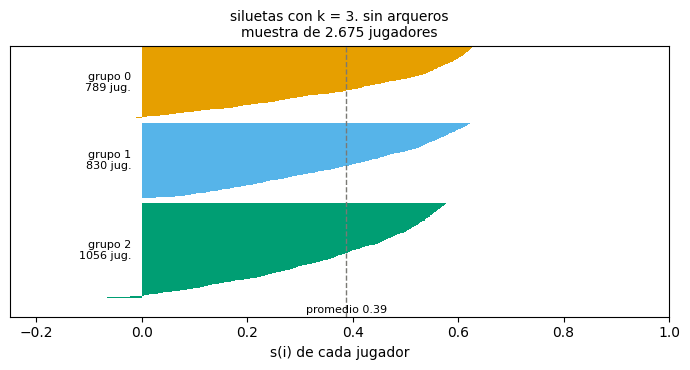

In [ ]:
graficar_siluetas(automatico_campo, X, f"siluetas con k = {K}, sin arqueros")

Las siluetas muestran lo que el 0,38 resumía, y comparadas con las de k = 2 se entienden solas:
tres figuras parejas en altura, todas angostas —casi nadie pasa de 0,6— y las tres bajan en rampa
hasta cero, con el grupo 2 asomando a los negativos: jugadores que están más cerca del centro de
otro grupo que del suyo, los que viven sobre las fronteras del plano. Son grupos de un degradé, no
bloques separados.

### 4.4 Lo que cambia en DBSCAN

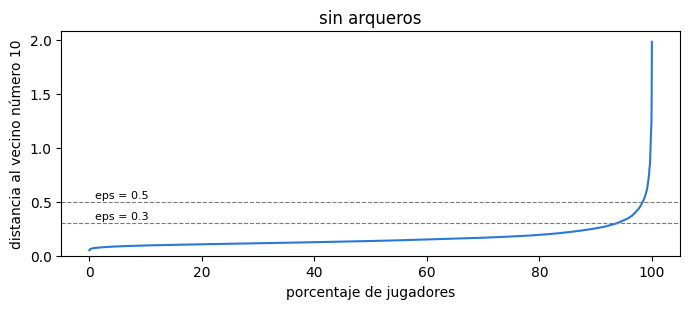

,grupos,ruido,tamaños
eps,,,
0.1,195,11361,"604, 203, 200"
0.2,37,1945,"14.403, 32, 29"
0.3,7,564,"16.153, 35, 22"
0.5,2,120,"16.688, 17"
0.8,1,27,16.798


In [ ]:
graficar_distancias(sin_arqueros(densidad(1))[:-1].fit_transform(X), [0.3, 0.5], "sin arqueros")
barrido_eps(lambda eps: sin_arqueros(densidad(eps)), X, [0.1, 0.2, 0.3, 0.5, 0.8])

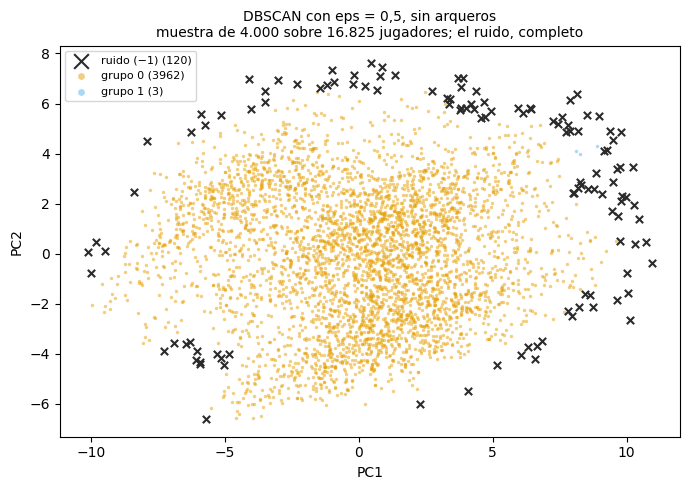

In [ ]:
densidad_campo = sin_arqueros(densidad(0.5)).fit(X)
graficar_grupos(densidad_campo, X, "DBSCAN con eps = 0,5, sin arqueros")

In [ ]:
# los del ruido, con nombre
etiqueta_db_campo = pd.Series(densidad_campo["dbscan"].labels_, index=campo.index)
df.loc[etiqueta_db_campo[etiqueta_db_campo == -1].index, ["short_name", "club_name", "overall", "attacking_finishing", "movement_sprint_speed", "defending_standing_tackle"]].assign(rol=rol).sort_values("overall", ascending=False).head(12)

,short_name,club_name,overall,attacking_finishing,movement_sprint_speed,defending_standing_tackle,rol
7745,K. Mbappé,Real Madrid,91,94,96,34,Delantero
2901,Vitinha,Paris Saint-Germain,90,81,69,79,Volante
2900,O. Dembélé,Paris Saint-Germain,90,90,89,49,Delantero
3924,H. Kane,FC Bayern München,90,96,65,44,Delantero
3925,J. Kimmich,FC Bayern München,89,68,70,86,Volante defensivo
1638,Rodri,Manchester City,89,74,65,87,Volante defensivo
1635,Gabriel,Arsenal,89,37,67,88,Defensor central
1636,M. Salah,Liverpool,89,88,86,43,Volante
7750,Vini Jr.,Real Madrid,89,87,93,25,Volante
7751,F. Valverde,Real Madrid,89,80,93,87,Volante


DBSCAN dice lo mismo con su definición: con `eps` chico la nube se desarma en pedacitos y ruido,
y en cuanto `eps` alcanza para que el centro de la nube se conecte (0,5), **un solo grupo** de 16.700
y 120 de ruido; con 0,8, uno solo y punto. No hay `eps` que devuelva tres grupos, ni dos: no hay
huecos que encontrar. Lo que sí devuelve, otra vez, es la lista de los que no tienen vecinos, y
otra vez son los mejores del mundo —Mbappé, Vitinha, Dembélé, Kane, Kimmich, Rodri, Salah,
Vinicius, Valverde, Bellingham…—, en la punta derecha del plano donde la nube se ralea.

Es la lección de la parte: **lo que un algoritmo encuentra depende de qué distancia se le da, y la
distancia la define el pipeline** —qué filas entran, qué columnas, cómo se escalan, sobre qué
proyección—. Con los arqueros, los dos algoritmos encontraron el mismo hueco. Sin ellos, k-means
corta igual, porque corta siempre, y DBSCAN se niega, porque no hay dónde cortar. Los tres grupos
de 4.3 no son mentira: son una partición útil de un degradé, defendible por su descripción y no por
su silhouette. Y la decisión de cuál de las dos respuestas usar es del analista, no del algoritmo.

## Parte 5 — Lo que le deja al supervisado

Nada de lo anterior predice. Pero PCA es un transformador, y un transformador entra en el pipeline
de las prácticas anteriores como un paso más de `preparar`: en lugar de darle al clasificador las
34 habilidades, darle las diez primeras componentes; o darle las dos cosas. La pregunta es si eso
mejora a alguno de los modelos de las Prácticas 1 y 2, y se contesta como todo: el mismo pipeline,
la misma partición de entrenamiento y prueba, el mismo f1 macro, cambiando sólo el paso.

El pipeline de la Práctica 1 preparaba las columnas numéricas (imputar, escalar) y las categóricas
(imputar, codificar). Acá `preparar_con` arma tres variantes de ese `ColumnTransformer`, que sólo
difieren en qué hace con las 34 habilidades detalladas; las otras 32 numéricas y las categóricas se
preparan igual en las tres. PCA se ajusta adentro del pipeline, así que aprende las direcciones sólo
con los jugadores de entrenamiento. Tres clasificadores, con los hiperparámetros que ganaron en la
Práctica 2: el lineal, el árbol solo y el conjunto de árboles.

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import f1_score

# la partición de siempre; hoy rol vuelve a ser y, sólo en esta parte
X_train, X_test, y_train, y_test = train_test_split(X, rol, test_size=0.2, stratify=rol, random_state=SEMILLA)

OTRAS = [c for c in NUMERICAS if c not in DETALLADAS]   # las numéricas que no son habilidades detalladas

def preparar_con(variante, n=10):
    '''El preparar de la Práctica 1, con las 34 habilidades (a) tal cual, (b) reemplazadas por n componentes, o (c) las dos cosas.'''
    numericas   = Pipeline([("imputar", SimpleImputer(strategy="median")), ("escalar", StandardScaler())])
    categoricas = Pipeline([("imputar", SimpleImputer(strategy="most_frequent")), ("codificar", OneHotEncoder(handle_unknown="ignore"))])
    componentes = Pipeline([("escalar", StandardScaler()), ("pca", PCA(n_components=n, random_state=SEMILLA))])
    pasos = [("otras", numericas, OTRAS), ("categoricas", categoricas, CATEGORICAS)]
    if variante in ("originales", "ambas"):
        pasos.append(("habilidades", clone(numericas), DETALLADAS))
    if variante in ("pca", "ambas"):
        pasos.append(("pca", componentes, DETALLADAS))
    return ColumnTransformer(pasos)

clasificadores = {"logística": lambda: LogisticRegression(max_iter=3000, C=10),
                  "árbol":     lambda: DecisionTreeClassifier(max_depth=15, min_samples_leaf=10, random_state=SEMILLA),
                  "boosting":  lambda: HistGradientBoostingClassifier(learning_rate=0.05, max_iter=300, max_leaf_nodes=15, random_state=SEMILLA)}

def medir(p):
    '''f1 macro en prueba de un pipeline ajustado en entrenamiento.'''
    return f1_score(y_test, p.fit(X_train, y_train).predict(X_test), average="macro")

# nueve pipelines
f1 = pd.DataFrame({variante: {modelo: medir(Pipeline([("preparar", preparar_con(variante)), ("clasificador", fabricar())]))
                              for modelo, fabricar in clasificadores.items()}
                   for variante in ["originales", "pca", "ambas"]})
f1.round(3)

,originales,pca,ambas
logística,0.834,0.820,0.834
árbol,0.736,0.734,0.748
boosting,0.821,0.791,0.815


In [ ]:
# la misma tabla, leída como ganancia respecto de las habilidades originales
f1.sub(f1["originales"], axis=0).round(3)

,originales,pca,ambas
logística,0.0,-0.014,0.001
árbol,0.0,-0.002,0.012
boosting,0.0,-0.030,-0.006


Tres lecturas, una por columna.

**Reemplazar las 34 habilidades por diez componentes** le cuesta a la logística (−0,014) y mucho
más al boosting (−0,030); al árbol casi nada. Diez componentes guardan el 90 % de la varianza, pero
varianza no es información sobre la etiqueta: el 10 % que se tira tenía algo que distinguía un
lateral de un volante, y los modelos lo notan.

**Darle las dos cosas** no le cambia nada a la logística (+0,001): una componente es una combinación
lineal de las 34 habilidades, y una combinación lineal es exactamente lo que una logística ya sabe
armar sola; no le dicen nada nuevo. Al boosting tampoco (−0,006, ruido de una partición): trescientos
árboles chicos en secuencia ya arman cualquier combinación que necesiten, por su cuenta. Al **árbol
solo** le da una centésima larga (0,736 → 0,748), y es el mismo efecto de las restas de la Práctica
2: un árbol corta una columna por vez, y una componente es un corte *oblicuo* —tantos puntos de
esto, menos tantos de aquello— servido en una columna; lo que al árbol le costaba una escalera de
cortes, en PC1 o PC2 es una pregunta.

Lo que PCA le deja al supervisado, entonces, no es «menos columnas y lo mismo»: es **columnas
nuevas para el modelo que no puede combinarlas solo**, y nada —o una pérdida— para los que sí
pueden, sea porque son lineales o porque son muchos.

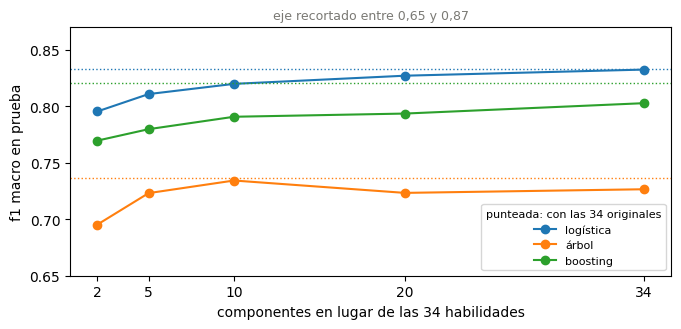

In [ ]:
# cuántas componentes: el n es un hiperparámetro, y se mide como cualquier otro
curva_n = pd.DataFrame({modelo: {n: medir(Pipeline([("preparar", preparar_con("pca", n)), ("clasificador", fabricar())]))
                                 for n in [2, 5, 10, 20, 34]}
                        for modelo, fabricar in clasificadores.items()})

fig, ax = plt.subplots(figsize=(7, 3.4))
for modelo in curva_n:
    ax.plot(curva_n.index, curva_n[modelo], marker="o", label=modelo)
    ax.axhline(f1.loc[modelo, "originales"], color=ax.lines[-1].get_color(), ls=":", lw=1)
ax.set_xlabel("componentes en lugar de las 34 habilidades"); ax.set_ylabel("f1 macro en prueba"); ax.set_ylim(0.65, 0.87)
ax.set_title("eje recortado entre 0,65 y 0,87", fontsize=9, color="#7a7974")
ax.set_xticks(curva_n.index); ax.legend(fontsize=8, title="punteada: con las 34 originales", title_fontsize=8)
plt.tight_layout()
plt.show()

La curva confirma la lectura, y agrega una. Para la logística, más componentes es siempre mejor y
con las 34 llega exactamente a lo que daban las 34 originales (0,833 contra 0,834): girar los ejes
no cambia un modelo lineal, y recortarlos sólo le quita. Para el árbol hay un óptimo en diez
componentes y con las 34 *baja*: las últimas componentes son ruido con nombre, y el árbol las usa.

El boosting es el caso que vale la pena mirar: con las 34 componentes —la misma información que
las 34 habilidades, sólo girada— queda en 0,803, casi dos centésimas abajo de las originales.
Para un modelo de árboles **los ejes importan**: «`goalkeeping_diving` mayor que 40» separa a los
arqueros con un corte; en componentes, ese mismo corte es una diagonal que hay que aproximar con
varios. La logística no ve la diferencia porque no corta: proyecta. Reducir dimensión con PCA no
es gratis, y a quién le sirve depende de cómo mira el modelo a las columnas.

### 5.1 Qué espera la Entrega 3 de un proyecto sin etiqueta

Cuatro grupos del integrador tienen un proyecto donde no hay `y`: segmentar, agrupar, encontrar
perfiles. Para ellos la Entrega 3 no pide una métrica contra una respuesta, porque no la hay; pide
lo que este notebook hizo, en este orden:

- **Las columnas elegidas y escaladas**, con el motivo, y como paso del pipeline. Qué entra en la
  distancia es la primera decisión del modelo, y la que más cambia el resultado.
- **k elegido con una medida interna** —silhouette, o el codo de la inercia— y la curva mostrada,
  desde *k* = 1, no sólo el valor. Con DBSCAN no se elige *k* sino `eps`, con la curva de la
  distancia al vecino; y el silhouette sirve para comparar los dos.
- **Los grupos descriptos**: el perfil promedio de cada uno, cuántos elementos tiene, y un nombre
  que se pueda defender. Un cluster sin descripción es un número.
- **La decisión sobre lo que domina**: si un grupo se lleva todo (los arqueros de acá), qué se
  hizo con él, como paso del pipeline, y qué cambió después.
- **Lo que no apareció.** Si la hipótesis era «hay cinco tipos de cliente» y silhouette dice dos,
  eso es el resultado, y se escribe.

Y una advertencia que vale para todos: un cluster no es una categoría que existía y se descubrió.
Es un corte que el algoritmo hizo porque se lo pidieron; si tiene sentido, lo tiene por la
descripción, no por el silhouette.

## Cierre

La pregunta era qué se puede aprender de los mismos datos sin la etiqueta. La respuesta, medida
dos veces: hay **dos** grupos —arqueros y jugadores de campo, con un silhouette de 0,70 y un hueco
que DBSCAN encuentra sin que nadie le diga cuántos buscar— y, adentro del campo, un **degradé** de
defensa a ataque cruzado por el nivel, sin huecos: k-means lo corta en tres porque corta siempre, y
DBSCAN lo deja en uno porque no hay dónde cortar. Los roles son nombres puestos sobre ese degradé.

Y todo lo que cambió a lo largo del notebook se explicó por un paso del pipeline: proyectar a dos
componentes fue una decisión; sacar a los arqueros cambió el escalado, la varianza, el sentido de
la tercera componente y lo que los dos algoritmos encontraron; elegir *k* fue un paso que se puede
leer en `k_` y en `barrido_`; elegir `eps` fue una curva y una elección escrita.

Tres cosas se llevan al integrador: la escala y la proyección son parte del modelo; *k* o `eps` se
eligen con una medida interna y se defienden con una descripción; y un cluster es un corte, no un
descubrimiento, hasta que alguien le pone un nombre que se sostiene. Y una cuarta, de la Parte 5:
lo que el no supervisado le deja al supervisado se mide, no se supone —y acá dio columnas nuevas
para el árbol solo, nada para la logística ni para el conjunto.

> Con esto termina la Unidad 3. Lo que sigue es la Unidad 4: cómo se muestra todo esto.